<a href="https://colab.research.google.com/github/willian82/repositoria-google-colad/blob/main/bloque_1_regresion_lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Celda 1: imports**

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

Qué hace: carga las herramientas que usaremos: pandas para tablas, matplotlib y seaborn para gráficos, kagglehub para descargar el dataset y scikit-learn para el modelo y las métricas.


### **Introducción al Bloque 1: Regresión Lineal Simple (Breast Cancer)**

En este primer bloque, utilizaremos el dataset *Breast Cancer Wisconsin* con el objetivo de comprender el comportamiento de la regresión lineal simple y responder a la pregunta fundamental: **¿Es suficiente un coeficiente de determinación ($R^2$) alto para validar la idoneidad de un modelo?**

Para ello:
1. Cargaremos y limpiaremos las variables.
2. Analizaremos las distribuciones de las variables clave: `radius_mean` (Radio medio), `perimeter_mean` (Perímetro medio) y `area_mean` (Área media).
3. Entrenaremos dos modelos de regresión lineal para predecir el Perímetro y el Área a partir del Radio.
4. Analizaremos las métricas y los residuos para entender el comportamiento geométrico y sus implicaciones.

# Celda 2: credenciales y descarga

In [ ]:
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

ruta = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Carpeta:", ruta)
print("Archivos:", os.listdir(ruta))

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Carpeta: /kaggle/input/breast-cancer-wisconsin-data
Archivos: ['data.csv']


# Celda 3: carga e inspección

In [ ]:
df = pd.read_csv(os.path.join(ruta, "data.csv"))

print("Dimensiones:", df.shape)
print("\nTipos de dato:")
print(df.dtypes)
print("\nColumnas con nulos:")
print(df.isnull().sum()[df.isnull().sum() > 0])
df.head()

Dimensiones: (569, 33)

Tipos de dato:
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_wors

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


# Celda 4: limpiar

In [ ]:
df = df.drop(columns=["id", "Unnamed: 32"])
print("Dimensiones después de limpiar:", df.shape)
print("Nulos totales:", df.isnull().sum().sum())

Dimensiones después de limpiar: (569, 31)
Nulos totales: 0


### **1. Justificación del Preprocesamiento y Limpieza de Datos**

Realizamos las siguientes acciones de limpieza sobre el dataset original:
* **Eliminación de `id`:** Se descarta esta columna debido a que es un identificador único y carece de poder predictivo o valor estadístico.
* **Eliminación de `Unnamed: 32`:** Se elimina por completo debido a que el 100% de sus registros contenían valores nulos (`NaN`), no aportando ninguna información útil.
* **Tratamiento de `diagnosis`:** Mantenemos esta variable diagnóstica únicamente para análisis y segmentación posterior (Benigno/Maligno), pero la excluimos del conjunto de variables predictoras numéricas del modelo lineal.

# Paso 2: EDA del Bloque 1

## Celda 5: histogramas y box-plots

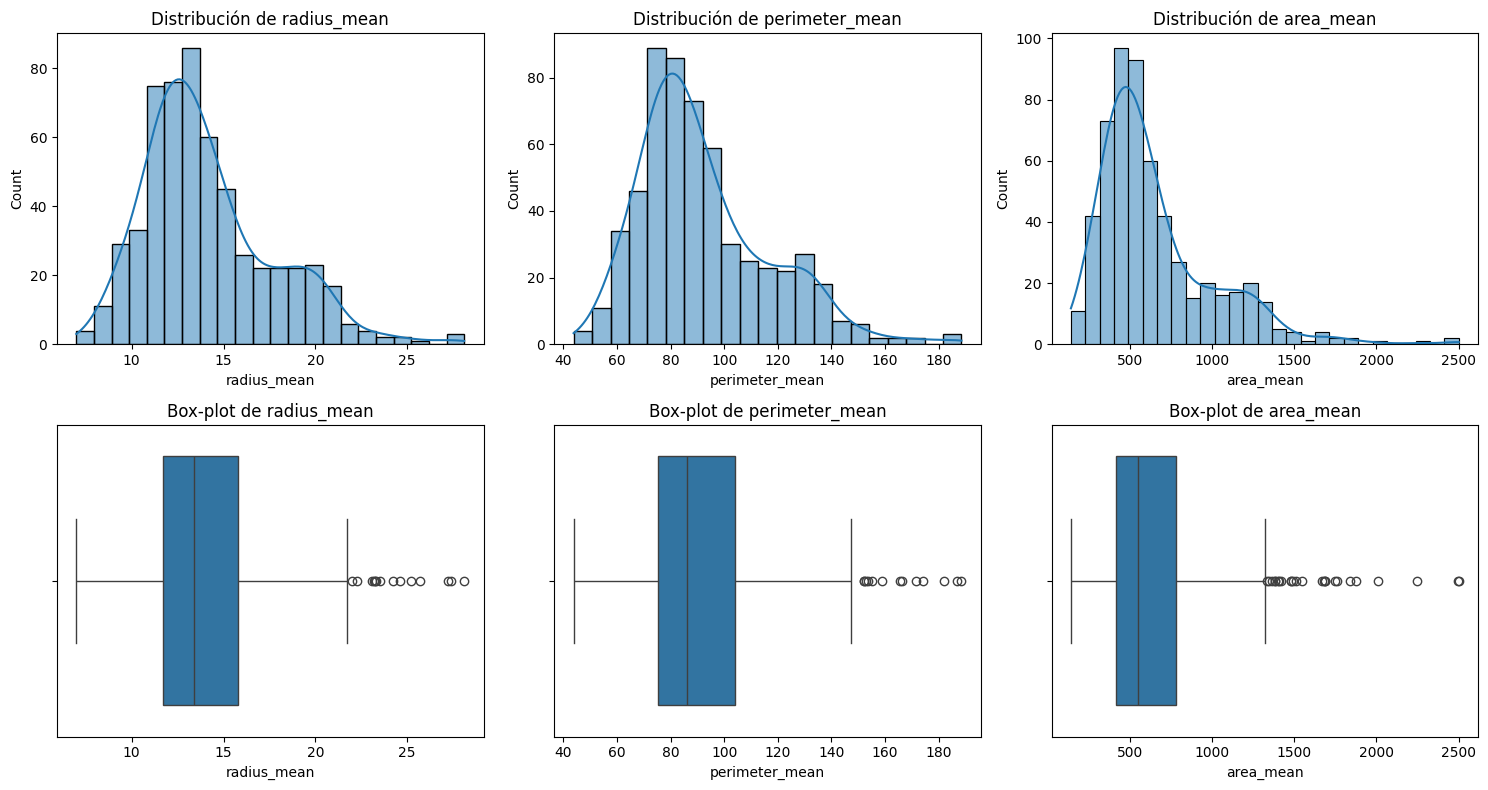

       radius_mean  perimeter_mean  area_mean
count       569.00          569.00     569.00
mean         14.13           91.97     654.89
std           3.52           24.30     351.91
min           6.98           43.79     143.50
25%          11.70           75.17     420.30
50%          13.37           86.24     551.10
75%          15.78          104.10     782.70
max          28.11          188.50    2501.00


In [ ]:
vars_modelo = ["radius_mean", "perimeter_mean", "area_mean"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, v in enumerate(vars_modelo):
    sns.histplot(df[v], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Distribución de {v}")
    sns.boxplot(x=df[v], ax=axes[1, i])
    axes[1, i].set_title(f"Box-plot de {v}")

plt.tight_layout()
plt.show()

print(df[vars_modelo].describe().round(2))

# Celda 6: mapa de correlaciones

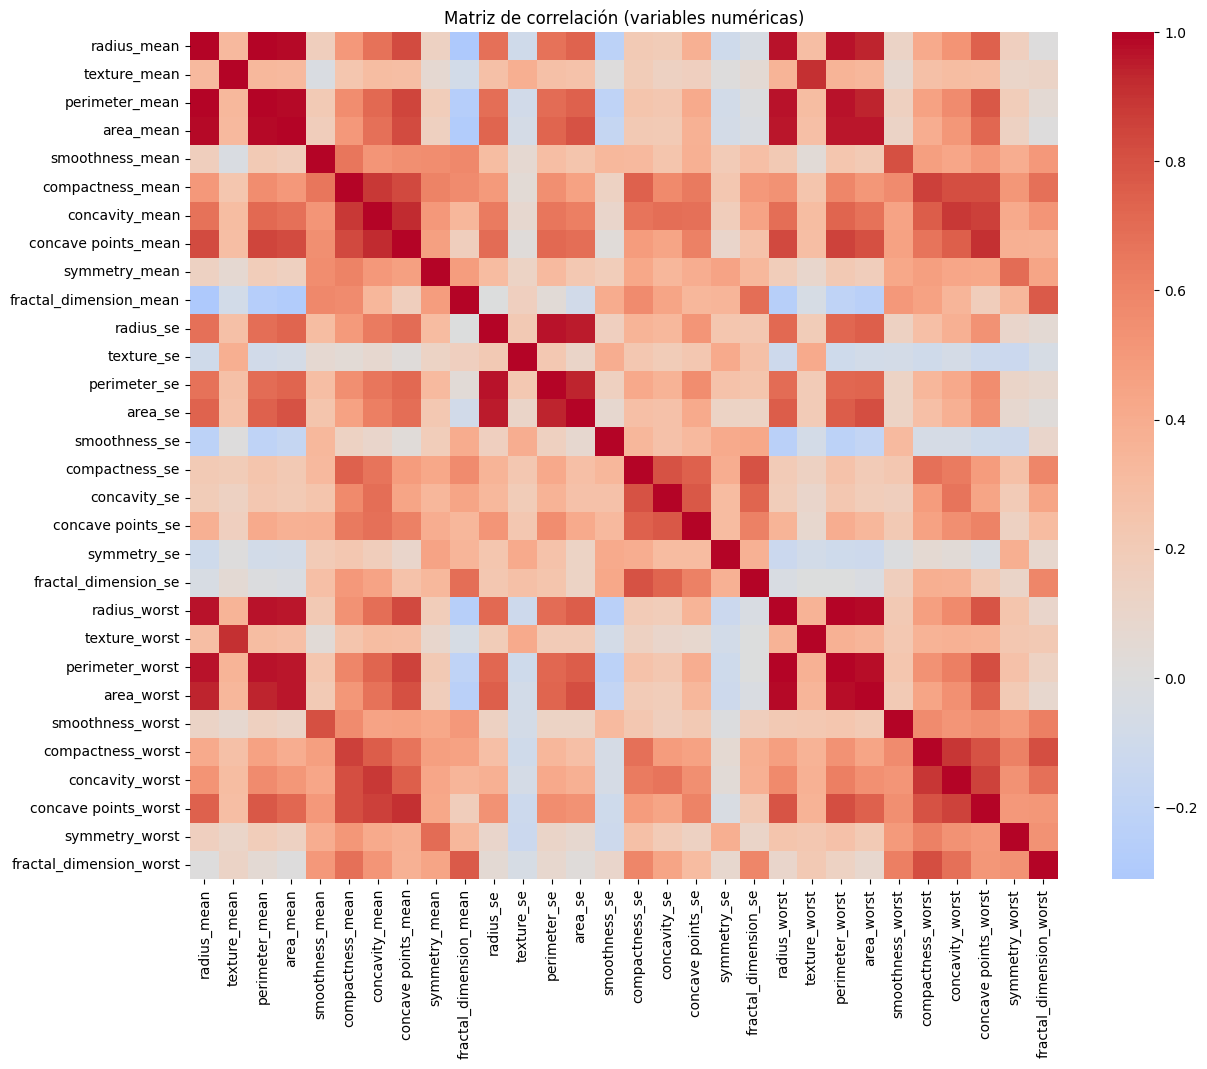

                radius_mean  perimeter_mean  area_mean
radius_mean           1.000           0.998      0.987
perimeter_mean        0.998           1.000      0.987
area_mean             0.987           0.987      1.000


In [ ]:
cols_num = df.drop(columns=["diagnosis"]).columns
corr = df[cols_num].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Matriz de correlación (variables numéricas)")
plt.show()

print(df[vars_modelo].corr().round(3))

### **2. Análisis Exploratorio de Datos (EDA)**

#### **A. Distribución y Forma de las Variables**
* Al inspeccionar los gráficos y las estadísticas descriptivas de `radius_mean`, `perimeter_mean` y `area_mean`, observamos una clara **asimetría positiva** (sesgo a la derecha).
* Esto se evidencia en que la **media** es significativamente mayor que la **mediana** en las tres variables:
  * `radius_mean`: Media de $14.13$ vs. Mediana de $13.37$
  * `perimeter_mean`: Media de $91.97$ vs. Mediana de $86.24$
  * `area_mean`: Media de $654.89$ vs. Mediana de $551.10$
* Adicionalmente, los *box-plots* muestran la presencia de valores atípicos (*outliers*) únicamente hacia el extremo derecho superior, siendo la variable `area_mean` la que cuenta con el sesgo más pronunciado (con valores máximos de hasta $2501.00$).

#### **B. Correlación y Justificación Geométrica**
* La matriz de correlación nos revela relaciones extremadamente fuertes y lineales:
  * Correlación entre Radio y Perímetro: $0.998$
  * Correlación entre Radio y Área: $0.987$
* Estas altas correlaciones tienen una **razón geométrica obvia**: el perímetro ($P \approx 2\pi r$) y el área ($A \approx \pi r^2$) se calculan directamente a partir del radio de la célula. Sin embargo, aunque la correlación sea casi perfecta, la naturaleza de ambas fórmulas es distinta (una es lineal y la otra es cuadrática), lo cual impactará directamente en el ajuste del modelo de regresión lineal simple.

# Siguiente: Paso 3, primer modelo

In [ ]:
X = df[["radius_mean"]]
y = df["perimeter_mean"]

modelo_per = LinearRegression()
modelo_per.fit(X, y)

print("Pendiente:", modelo_per.coef_[0])
print("Intercepto:", modelo_per.intercept_)

Pendiente: 6.880400289601538
Intercepto: -5.232388786540255


### **3. Interpretación del Modelo 1: Perímetro ~ Radio**

ras entrenar el modelo obtenemos los siguientes coeficientes:

* **Pendiente (coeficiente):** $6.88$

* **Interpretación:** Por cada unidad de aumento en el radio medio de la célula, el perímetro medio aumenta, en promedio, $6.88$ unidades. Este número es cercano a $2\pi \approx 6.28$; es ligeramente superior porque los núcleos celulares no son círculos perfectos y tienen rugosidades que extienden el perímetro.

* **Intercepto:** $-5.23$

* **Interpretación:** Físicamente, un radio de 0 debería resultar en un perímetro de 0. El intercepto negativo representa una extrapolación matemática sin sentido biológico (ya que el radio mínimo real registrado es $6.98$), actuando meramente como una constante de ajuste para la recta.

# Paso 4: segundo modelo (area_mean)

In [ ]:
X = df[["radius_mean"]]
y = df["area_mean"]

modelo_area = LinearRegression()
modelo_area.fit(X, y)

print("Pendiente:", modelo_area.coef_[0])
print("Intercepto:", modelo_area.intercept_)

Pendiente: 98.59821921514533
Intercepto: -738.0367041957495


### **4. Interpretación del Modelo 2: Área ~ Radio**

Aquí está la información proporcionada por el usuario:

Tras entrenar el segundo modelo obtenemos los siguientes coeficientes:

* **Pendiente (coeficiente):** $98.60$

* *Interpretación:* En promedio, cada vez que el radio aumenta en una unidad, la pendiente muestra que el área estimada aumenta en $98.60$ unidades. La relación real es cuadrática ($A \approx \pi r^2$). La pendiente no es constante. La recta solo intenta promediar este crecimiento exponencial.

* **Intercepto:** $-738.04$

* *Interpretación:* El intercepto es $-738.04$. Este valor negativo muestra que la aproximación lineal no funciona bien cuando el radio es bajo. Para intentar igualar la curvatura de la parábola con una recta, el intercepto se fuerza muy bajo, lo que sugiere áreas negativas cuando el radio es pequeño.

# Paso 5: evaluación con partición 80/20

In [ ]:
X = df[["radius_mean"]]

resultados = {}
modelos = {}
datos_prueba = {}

for nombre, objetivo in [("perimeter_mean", "perimeter_mean"), ("area_mean", "area_mean")]:
    y = df[objetivo]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    m = LinearRegression().fit(X_train, y_train)
    y_pred = m.predict(X_test)

    resultados[nombre] = {
        "R2": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    }
    modelos[nombre] = m
    datos_prueba[nombre] = (X_test, y_test, y_pred)

print(pd.DataFrame(resultados).T.round(3))

                   R2     MAE    RMSE
perimeter_mean  0.996   1.042   1.583
area_mean       0.981  34.975  46.578


### **5. Análisis Comparativo con Validación Cruzada (80/20)**

Comparando las métricas en el conjunto de prueba, observamos lo siguiente:

1. **Coeficiente de Determinación ($R^2$):**
   * El modelo de perímetro cuenta con un $R^2 = 0.996$ y el de área con un $R^2 = 0.981$. A simple vista, ambos parecen excelentes por estar sumamente cerca a 1.
2. **Magnitud de los Errores (MAE y RMSE):**
   * Para el **Perímetro**: El MAE es de $1.04$ frente a una media de $\approx 92$ (un error relativo de aproximadamente el **1.1%**).
   * Para el **Área**: El MAE es de $34.97$ frente a una media de $\approx 655$ (un error relativo de aproximadamente el **5.3%**).
   * El error relativo del modelo de área es 5 veces mayor al del perímetro, diferencia que la simple vista del $R^2$ no deja ver con facilidad.

# Paso 6: visualización (regresión y residuos)

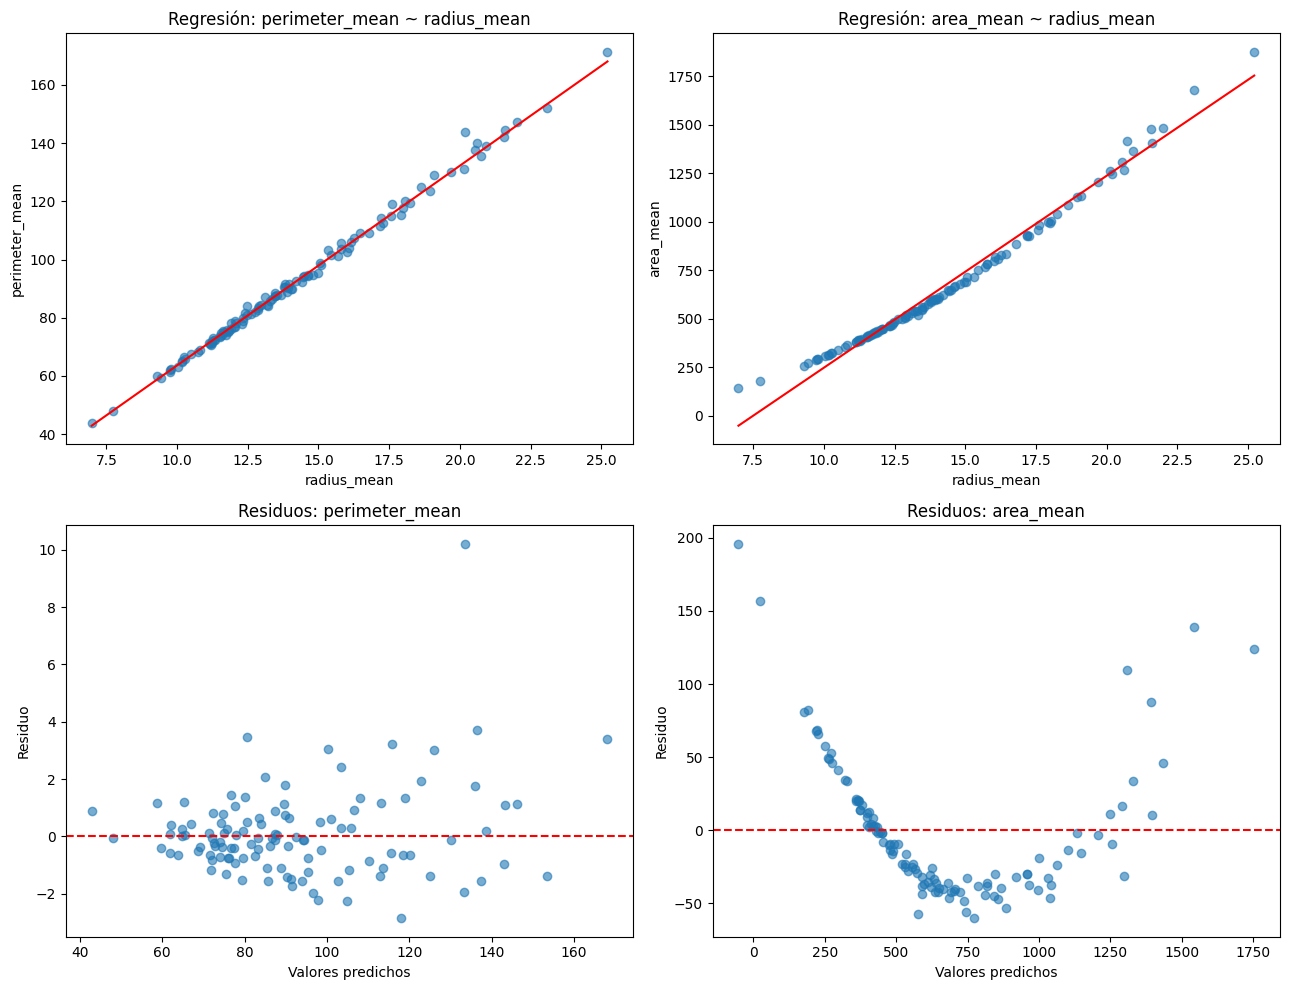

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for j, nombre in enumerate(["perimeter_mean", "area_mean"]):
    X_test, y_test, y_pred = datos_prueba[nombre]
    residuos = y_test - y_pred

    # Regresión: nube de puntos + recta
    ax = axes[0, j]
    ax.scatter(X_test["radius_mean"], y_test, alpha=0.6)
    orden = np.argsort(X_test["radius_mean"].values)
    ax.plot(X_test["radius_mean"].values[orden], y_pred[orden], color="red")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel(nombre)
    ax.set_title(f"Regresión: {nombre} ~ radius_mean")

    # Residuos vs predichos
    ax = axes[1, j]
    ax.scatter(y_pred, residuos, alpha=0.6)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_xlabel("Valores predichos")
    ax.set_ylabel("Residuo")
    ax.set_title(f"Residuos: {nombre}")

plt.tight_layout()
plt.show()

### **6. Diagnóstico de Residuos e Interpretación Final del Bloque 1**

El análisis visual de las regresiones y los gráficos de residuos es importante para comprobar los supuestos del modelo lineal:

* **Modelo 1: Perímetro ($R^2 = 0.996$):**
* Los residuos están distribuidos de manera aleatoria y uniforme alrededor del cero (homocedasticidad). La suposición de linealidad está completamente cumplida.

* **Modelo 2: Área ($R^2 = 0.981$):**
* Aunque el $R^2$ es muy alto, el gráfico de residuos muestra un patrón claro en forma de “U” (residuos positivos en los extremos y negativos en el centro).

* Esto indica que el modelo subestima el área para radios muy pequeños y muy grandes, y la sobreestima para radios intermedios. Además, el modelo predice áreas negativas para radios pequeños.

#### **Conclusión e Hipótesis de Transformación:**

Un $R^2$ alto no es suficiente para asegurar que un modelo de regresión lineal sea adecuado. Los residuos son la mejor forma de identificar la falta de linealidad.

Para resolver el problema del modelo de área, se necesitaría aplicar una transformación no lineal a las variables, como predecir la raíz cuadrada del área ($\sqrt{\text{Area}}$), lo cual mantendría una relación estrictamente lineal con el radio.